# **PART B — Linear Regression From Scratch:**

## **Problem Statements:**

## **B1. Implement the prediction function:**

Write:
```python
def predict(x, w, b):    # your implementation    
    pass
```
Requirements:
- Accept an individual input.
- Calculate its prediction using the linear model.
- Test your function with at least three different weight and bias combinations.

## **B2. Implement the cost function:**
Implement:
$$J(w,b)=\frac{1}{2m}\sum_{i=1}^{m}(wx^{(i)}+b-y^{(i)})^2$$

Write:
```python
def compute_cost(x, y, w, b):    
    pass
```

Requirements:
1. Use a loop.
2. Do not use Scikit-learn.
3. Test at least five combinations of w and b.
4. Identify which combination produces the smallest cost.
Create a cost-versus-weight plot while keeping bias fixed at zero.

Then explain why the cost changes as the weight changes.

## **B3. Implement gradient calculation:**

Implement:
$$\frac{\partial J}{\partial w} = \frac{1}{m}\sum_{i=1}^{m}(wx^{(i)}+b-y^{(i)})x^{(i)}\$$

$$\frac{\partial J}{\partial b} = \frac{1}{m}\sum_{i=1}^{m}(wx^{(i)}+b-y^{(i)})\$$

Write:
```python
def compute_gradient(x, y, w, b):
    pass
```

Requirements:
- Your function should return two values.
- Test your implementation with different initial weights and biases.

## **B4. Implement batch gradient descent**

Write the complete algorithm:
```python
def gradient_descent(x, y, w_in, b_in, alpha, iterations):
    pass
```

Requirements:
- Initialize the parameters.
- Calculate gradients.
- Update weight and bias.
- Store cost history.
- Return the final parameters.
- Return the cost history.

Use:
```python
w_init = 0
b_init = 0
alpha = 0.01
iterations = 1000
```

Plot:
1. Cost against iterations.
2. Predicted regression line against training points.

## **B5. Learning-rate investigation**

Repeat your experiment with:
```python
learning_rates = [0.001, 0.01, 0.1, 0.5]
```

For each learning rate:
- Record final cost.
- Record final weight.
- Record final bias.
- Plot the cost history.

Answer:
1. Which learning rate converges fastest?
2. Can increasing the learning rate always speed up learning?
3. What happens when the learning rate is too large?
4. Why might a small learning rate require more iterations?

> **Note:** Do not assume a learning rate is appropriate just because the algorithm executes without producing an error.

## **Dataset:**

```python
import numpy as np
import matplotlib.pyplot as plt

x_train = np.array([1.0, 2.0, 3.0, 4.0, 5.0])
y_train = np.array([300.0, 500.0, 700.0, 900.0, 1100.0])
```

The input represents house size in thousands of square feet, and the target represents house price in thousands of dollars.

## **Solution:**

### B1

In [1]:
import numpy as np
import matplotlib.pyplot as plt

X_train = np.array([1.0, 2.0, 3.0, 4.0, 5.0])
y_train = np.array([300.0, 500.0, 700.0, 900.0, 1100.0])

In [3]:
def predict(x, w, b):
    """
    We know that in linear regression the model for prediction is:
                        y_hat = wx + b
    where;
    w --> is the the weight or slope mostly we call it as weight
    b --> is intercept or bias
    """

    prediction = (w*x) + b

    return prediction

In [6]:
w_1 = 1.5
b_1 = 1.25

w_2 = 4
b_2 = 2.5

w_3 = 20
b_3 = 15

print(f"The prediction when X is {X_train[0]}, weight is {w_1} and bias is {b_1}:", predict(X_train[0], w_1, b_1))
print(f"The prediction when X is {X_train[0]}, weight is {w_2} and bias is {b_2}:", predict(X_train[0], w_2, b_2))
print(f"The prediction when X is {X_train[0]}, weight is {w_3} and bias is {b_3}:", predict(X_train[0], w_3, b_3))

The prediction when X is 1.0, weight is 1.5 and bias is 1.25: 2.75
The prediction when X is 1.0, weight is 4 and bias is 2.5: 6.5
The prediction when X is 1.0, weight is 20 and bias is 15: 35.0


### B2

In [15]:
# we need to compute a cost function
def compute_cost(x, y, w, b):
    """
    As we know the cost is given as:
                J(w,b) = (1/2m)∑_{i=1}^n (f(w,b) - y) ** 2
    """
    m = x.shape[0]
    cost_sum = 0.

    for i in range(m):
        f_wb = (w * x[i]) + b
        cost = (f_wb - y[i]) ** 2
        cost_sum += cost
    total_cost = (1 / (2 * m)) * cost_sum

    return round(total_cost, 2)


In [16]:
combinations = [
    (2.5, 1.0),
    (-0.8, 5.0),
    (1.0, 0.0),
    (0.0, -3.5),
    (0.005, -0.12),
]

cost = []


for w, b in combinations:
    cost.append(compute_cost(X_train, y_train, w, b))

for (w,b),c in zip(combinations, cost):
    print(f"The cost when {w} is 2.5 and b is {b}: {c}")



The cost when 2.5 is 2.5 and b is 1.0: 278092.38
The cost when -0.8 is 2.5 and b is 5.0: 283504.02
The cost when 1.0 is 2.5 and b is 0.0: 282505.5
The cost when 0.0 is 2.5 and b is -3.5: 287456.12
The cost when 0.005 is 2.5 and b is -0.12: 285071.51


In [17]:
min_cost = min(cost)
best_w, best_b = combinations[cost.index(min_cost)]
print(f"The min cost is {min_cost} when w is {best_w} and b is {best_b}")

The min cost is 278092.38 when w is 2.5 and b is 1.0


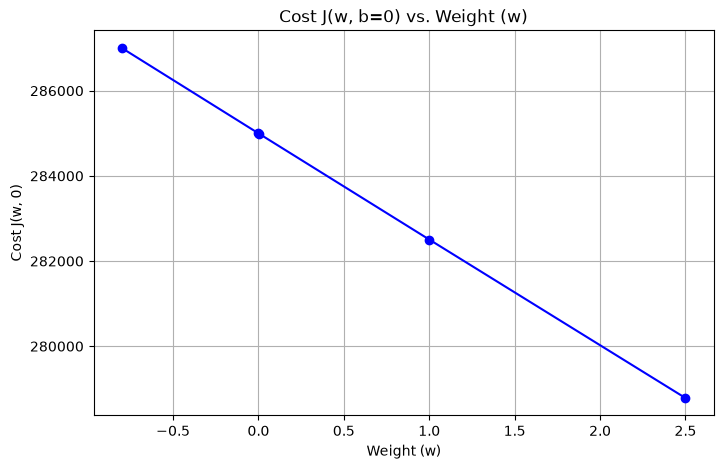

In [22]:
import matplotlib.pyplot as plt

# extract the w values from combinations previously used
w_vals = sorted([w for w,b in combinations])

# computing cost for each value when bias is 0
costs = [compute_cost(X_train, y_train, w, 0) for w in w_vals]

plt.figure(figsize=(8, 5))
plt.plot(w_vals, costs, marker='o', color='blue')
plt.title("Cost J(w, b=0) vs. Weight (w)")
plt.xlabel("Weight (w)")
plt.ylabel("Cost J(w, 0)")
plt.grid(True)
plt.show()

### B3

In [23]:
def compute_gradient(x, y, w, b):

    m = x.shape[0]
    dj_dw = 0
    dj_db = 0

    for i in range(m):
        f_wb = (w*x[i]) + b
        err = f_wb - y[i]

        dj_dw += err * x[i]
        dj_db += err

    dj_dw = dj_dw / m
    dj_db = dj_db / m

    return dj_dw, dj_db

In [24]:
test_params = [
    (0, 0),       # Starting at zero (under-predicting)
    (100, 50),    # Halfway to optimal (under-predicting)
    (200, 100),   # Exact solution (y = 200x + 100)
    (250, 150)    # Above optimal (over-predicting)
]

for w, b in test_params:
    dj_dw, dj_db = compute_gradient(X_train, y_train, w, b)
    print(f"w = {w}, b = {b}  -->  dj_dw = {dj_dw}, dj_db = {dj_db}")


w = 0, b = 0  -->  dj_dw = -2500.0, dj_db = -700.0
w = 100, b = 50  -->  dj_dw = -1250.0, dj_db = -350.0
w = 200, b = 100  -->  dj_dw = 0.0, dj_db = 0.0
w = 250, b = 150  -->  dj_dw = 700.0, dj_db = 200.0


### B4

In [67]:
def gradient_descent(x, y, w_in, b_in, alpha, iterations):
    """
    w_j+1 = w_j - alpha*dJ_dw
    b_j+1 = b_j - alpha*dJ_db 
    """

    J_history = []

    w = w_in
    b = b_in

    for i in range(iterations):
        
        dj_dw, dj_db = compute_gradient(x, y, w, b)

        w = w - (alpha * dj_dw)
        b = b - (alpha * dj_db)

        cost = compute_cost(x, y, w, b)

        J_history.append(cost)

        if i % (iterations // 10) == 0:

            print(f"Iteration {i}: w = {w:.4f}, b = {b:.4f}, cost = {cost:.4f}")

    return w, b, J_history

In [68]:
w_init = 0
b_init = 0
alpha = 0.01
iterations = 10000

final_w, final_b, cost_history = gradient_descent(X_train, y_train, w_init, b_init, alpha, iterations)

print(f"\nfinal weight is {final_w:.4f} and final bias is {final_b:.4f}\n")


Iteration 0: w = 25.0000, b = 7.0000, cost = 221587.0000
Iteration 1000: w = 202.1096, b = 92.3838, cost = 5.2800
Iteration 2000: w = 200.3885, b = 98.5973, cost = 0.1800
Iteration 3000: w = 200.0716, b = 99.7417, cost = 0.0100
Iteration 4000: w = 200.0132, b = 99.9524, cost = 0.0000
Iteration 5000: w = 200.0024, b = 99.9912, cost = 0.0000
Iteration 6000: w = 200.0004, b = 99.9984, cost = 0.0000
Iteration 7000: w = 200.0001, b = 99.9997, cost = 0.0000
Iteration 8000: w = 200.0000, b = 99.9999, cost = 0.0000
Iteration 9000: w = 200.0000, b = 100.0000, cost = 0.0000

final weight is 200.0000 and final bias is 100.0000



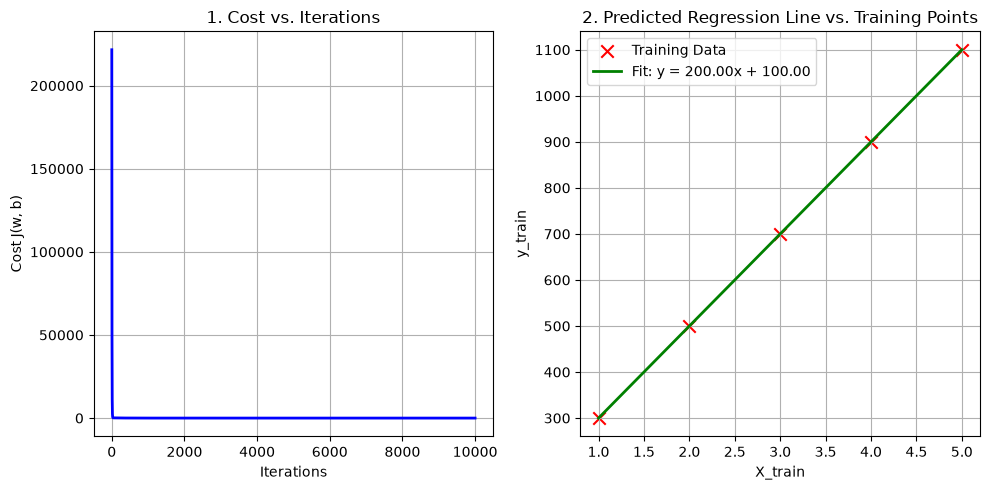

In [ ]:
# Create a 2x2 grid of subplots
fig, axs = plt.subplots(1, 2, figsize=(10, 5))

# 1. Cost against iterations
axs[0].plot(range(iterations), cost_history, color='blue', linewidth=2)
axs[0].set_title("1. Cost vs. Iterations")
axs[0].set_xlabel("Iterations")
axs[0].set_ylabel("Cost J(w, b)")
axs[0].grid(True)

# 2. Predicted regression line against training points
y_pred = (final_w * X_train) + final_b
axs[1].scatter(X_train, y_train, color='red', marker='x', s=80, label='Training Data')
axs[1].plot(X_train, y_pred, color='green', linewidth=2, label=f'Fit: y = {final_w:.2f}x + {final_b:.2f}')
axs[1].set_title("2. Predicted Regression Line vs. Training Points")
axs[1].set_xlabel("X_train")
axs[1].set_ylabel("y_train")
axs[1].legend()
axs[1].grid(True)


plt.tight_layout()
plt.show()


In [74]:
w_init = 0
b_init = 0
learning_rates = [0.001, 0.01, 0.1, 0.5] 
iterations = 10000    

--- Running Gradient Descent with alpha = 0.001 ---
Iteration 0: w = 2.5000, b = 0.7000, cost = 278299.8700
Iteration 1000: w = 209.6863, b = 65.0239, cost = 111.3300
Iteration 2000: w = 208.1809, b = 70.4645, cost = 79.3900
Iteration 3000: w = 206.9084, b = 75.0586, cost = 56.6100
Iteration 4000: w = 205.8338, b = 78.9381, cost = 40.3700
Iteration 5000: w = 204.9264, b = 82.2141, cost = 28.7900
Iteration 6000: w = 204.1601, b = 84.9806, cost = 20.5300
Iteration 7000: w = 203.5131, b = 87.3168, cost = 14.6400
Iteration 8000: w = 202.9666, b = 89.2896, cost = 10.4400
Iteration 9000: w = 202.5052, b = 90.9555, cost = 7.4400
--- Running Gradient Descent with alpha = 0.01 ---
Iteration 0: w = 25.0000, b = 7.0000, cost = 221587.0000
Iteration 1000: w = 202.1096, b = 92.3838, cost = 5.2800
Iteration 2000: w = 200.3885, b = 98.5973, cost = 0.1800
Iteration 3000: w = 200.0716, b = 99.7417, cost = 0.0100
Iteration 4000: w = 200.0132, b = 99.9524, cost = 0.0000
Iteration 5000: w = 200.0024, b = 

C:\Users\Zamzam Laptops\AppData\Local\Temp\ipykernel_19544\905163398.py:16: RuntimeWarning: overflow encountered in multiply
  return round(total_cost, 2)
C:\Users\Zamzam Laptops\AppData\Local\Temp\ipykernel_19544\905163398.py:12: RuntimeWarning: overflow encountered in scalar power
  cost = (f_wb - y[i]) ** 2
C:\Users\Zamzam Laptops\AppData\Local\Temp\ipykernel_19544\1177443826.py:11: RuntimeWarning: overflow encountered in scalar add
  dj_dw += err * x[i]
C:\Users\Zamzam Laptops\AppData\Local\Temp\ipykernel_19544\472733161.py:16: RuntimeWarning: invalid value encountered in scalar subtract
  w = w - (alpha * dj_dw)


Iteration 6000: w = nan, b = nan, cost = nan
Iteration 7000: w = nan, b = nan, cost = nan
Iteration 8000: w = nan, b = nan, cost = nan
Iteration 9000: w = nan, b = nan, cost = nan


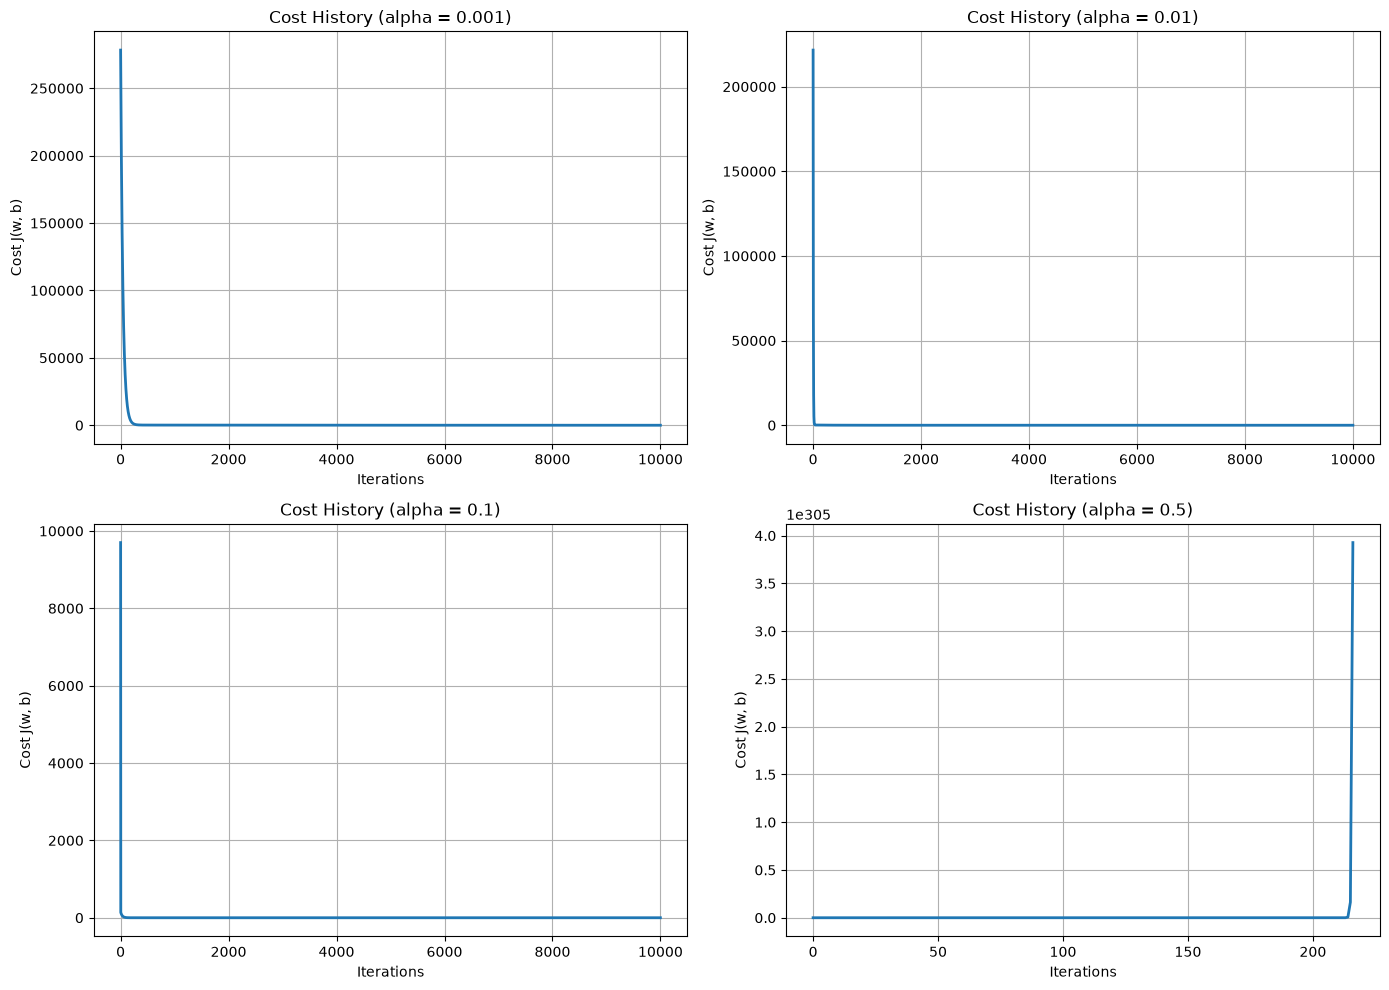


=== Summary of Learning Rate Investigation ===
alpha = 0.001  | Final Cost: 5.3100       | Final w: 202.1159   | Final b: 92.3610   
alpha = 0.01   | Final Cost: 0.0000       | Final w: 200.0000   | Final b: 100.0000  
alpha = 0.1    | Final Cost: 0.0000       | Final w: 200.0000   | Final b: 100.0000  
alpha = 0.5    | Final Cost: nan          | Final w: nan        | Final b: nan       


In [73]:
results = []
fig, axs = plt.subplots(2, 2, figsize=(14, 10))
axs = axs.flatten()  # Turns 2x2 grid into a flat list [0, 1, 2, 3]

for i, alpha in enumerate(learning_rates):
    print(f"--- Running Gradient Descent with alpha = {alpha} ---")
    final_w, final_b, cost_history = gradient_descent(
        X_train, y_train, w_init, b_init, alpha, iterations
    )
    final_cost = cost_history[-1]
    results.append((alpha, final_cost, final_w, final_b))
    
    # Plot cost history for this learning rate
    axs[i].plot(range(iterations), cost_history, linewidth=2)
    axs[i].set_title(f"Cost History (alpha = {alpha})")
    axs[i].set_xlabel("Iterations")
    axs[i].set_ylabel("Cost J(w, b)")
    axs[i].grid(True)

plt.tight_layout()
plt.show()

# Print clean summary table of recorded results
print("\n=== Summary of Learning Rate Investigation ===")
for alpha, f_cost, f_w, f_b in results:
    print(f"alpha = {alpha:<6} | Final Cost: {f_cost:<12.4f} | Final w: {f_w:<10.4f} | Final b: {f_b:<10.4f}")
